Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_34 (Dense)                     │ (None, 32)                  │             992 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_35 (Dense)                     │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_36 (Dense)                     │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_37 (Dense)                     │ (None, 30)                  │             990 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,054 (11.93 KB)

 Trainable params: 3,054 (11.93 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9437 - loss: 0.0039 - val_accuracy: 0.8079 - val_loss: 0.0014
Epoch 2/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9916 - loss: 0.0011 - val_accuracy: 0.8079 - val_loss: 8.9444e-04
Epoch 3/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9917 - loss: 6.7799e-04 - val_accuracy: 0.8079 - val_loss: 6.4038e-04
Epoch 4/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9917 - loss: 4.9503e-04 - val_accuracy: 0.8079 - val_loss: 5.3534e-04
Epoch 5/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9917 - loss: 4.3762e-04 - val_accuracy: 0.8081 - val_loss: 4.9779e-04
Epoch 6/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9917 - loss: 3.8599e-04 - val_accuracy: 0.8085 - val_loss: 4.3286e-04
Epoch 7/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9918 - loss: 3.3092e-04 - val_accuracy: 0.8085 - val_loss: 4.0030e-04
Epoch 8/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accura

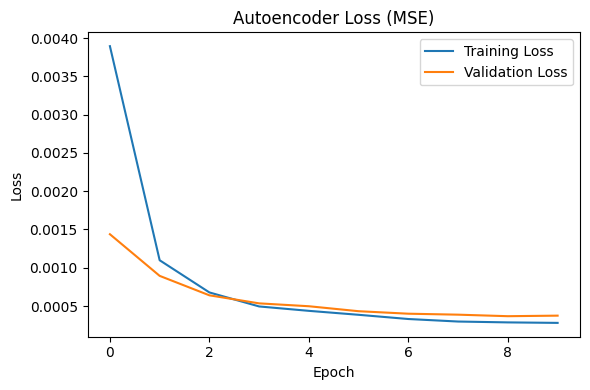

In [11]:
# 3A - Credit Card Fraud Detection using Autoencoder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report
from tensorflow import keras


# 1. LOAD DATASET
data = pd.read_csv("creditcard.csv")

# Separate features and target
x = data.drop("Class", axis=1).values
y = data["Class"].values      # 0 = Normal, 1 = Fraud


# 2. SCALE FEATURES BETWEEN 0 AND 1
scaler = MinMaxScaler()
x = scaler.fit_transform(x)


# 3. USE ONLY NORMAL TRANSACTIONS FOR TRAINING
x_normal = x[y == 0]


# 4. CREATE AUTOENCODER MODEL
n = x.shape[1]

model = keras.Sequential([
    # Encoder
    keras.layers.Input(shape=(n,)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(16, activation="relu"),

    # Decoder
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(n, activation="sigmoid")
])


# 5. COMPILE MODEL
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=['accuracy']
)

model.summary()


# 6. TRAIN THE AUTOENCODER
# Input and output are the same because the model learns reconstruction
history = model.fit(
    x_normal,
    x_normal,
    epochs=10,
    batch_size=256,
    validation_split=0.2,
    verbose=1
)


# 7. PREDICT / RECONSTRUCT ALL TRANSACTIONS
reconstructed = model.predict(x, verbose=0)


# 8. CALCULATE RECONSTRUCTION ERROR
error = np.mean(np.square(x - reconstructed), axis=1)


# 9. SET THRESHOLD
# 95th percentile of normal transaction errors
threshold = np.percentile(error[y == 0], 95)

print("\nThreshold:", threshold)


# 10. CLASSIFY TRANSACTIONS
# Error greater than threshold = Fraud
y_pred = (error > threshold).astype(int)


# 11. DISPLAY RESULTS
print("\nClassification Report:")
print(classification_report(y, y_pred))


# 12. PLOT TRAINING AND VALIDATION LOSS
plt.figure(figsize=(6, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Loss (MSE)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()

plt.show()